# Plasma solution simulation



In [135]:
a = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

b= a[:5 // 2 + 1]
print(b)

[1 2 3]


## Functions

In [120]:
def initialise_ionosphere_region(df, region):
    """ takes a dataframe of ionospheric properties and pulls the associated properties for a given region. making the necessary calculations required to run simulation CURRENTLY NOT ABLE TO HANDLE GEO"""

    # Pulls property name and values into a list and numpy array respectively
    value = df_ionosphere[region].to_numpy()
    properties = df_ionosphere["Properties"].to_list()

    # Creates a dictionary of the properties and values for the given region
    plasma_properties = dict(zip(properties, value))
    return plasma_properties


def normalised_plasma_potential(a, debye_length, mass_ratio, potential_radius=None):
    """Calculates the normalised plasma potential for a given debris radius, debye length, and mass ratio."""
    def _eqn_surface_potential(x, mass_ratio, s, a):
        """Equation 32 from the NASA paper in the form 0 = f(x) where f(x) is equal to g(x) - A(1-B * e(Cx), this equation is then put through brents method to identify the roots of the function, eφ/kT"""
        return np.exp(x) - np.sqrt(mass_ratio) * (s / a) ** 2 * (1 - ((s ** 2 - a ** 2) / s ** 2) * np.exp((a ** 2 / (s ** 2 - a ** 2)) * x))

    # If potential_radius is not provided, it defaults to the debye_length.
    if potential_radius is None:
        potential_radius = debye_length

    s = a + debye_length

    x_sol = brentq(_eqn_surface_potential, -10, 0, args=(mass_ratio, s, a))
    phi_np = x_sol * np.exp(-potential_radius / debye_length)  # normalised plasma potential

    return phi_np


def forcing_term_general(np_potential=None, x=None, time=None, vd=None, G=None):
    """ Calculates the forcing term for the normalised forced KdV equation
        Parameters: X IS XI AND TIME IS TAU
        Returns: Forcing term as a numpy array
    """
    return np_potential * np.exp(-1 * ((x - (vd * time)) / G) ** 2)


def ck_solver(last_sol, current_sol, alpha, beta, k, f, dt, s):
    """Use the Crank-Nicolson scheme to solve the normalised forced KdV equation on a non-periodic domain."""
    # pre-calculating coefficients
    _ck_beta = dt * beta * 1j * (k ** 3) * (s ** 3)
    _ck_z = dt * 1j * k * s

    # computing the rfft of u & f halfs the length of array which then is multipled by 1024 leng coefficents arrays because of k
    _ck_beta_fft = _ck_beta[:len(k) // 2 + 1]  # Keep only first 513 elements
    _ck_z_fft = _ck_z[:len(k) // 2 + 1]

    # Fourier transform of the last solution, current solution, and forcing term
    fft_last = rfft(last_sol)
    fft_current_sqrd = rfft(current_sol ** 2)
    fft_f = rfft(f)

    return irfft(((1 - _ck_beta_fft) ** -1) * ((1 + _ck_beta_fft) * fft_last - alpha * _ck_z_fft * fft_current_sqrd + _ck_z_fft * fft_f))

## Imports & variables

In [121]:
## Imports & variables
import numpy as np
from numpy.fft import rfft, irfft
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

df_ionosphere = pd.read_excel(r'Ionosphere prop.xltx') # Upload the Ionosphere properties from the Excel file
plasma_prop = initialise_ionosphere_region(df_ionosphere, "Low LEO") # Pulls the properties for the Low LEO region into a dictionary
display(df_ionosphere)

# Global constants
__kb__ = 1.380649e-23  #Boltzmann constant in J/K
__c__ = 299792458.0  # Speed of light in m/s
__me__ = 9.1093837139e-31  # Electron mass in kg
__mh__ = 1.67262192595e-27  # Hydrogen ion aka proton mass in kg
__mo__ = 15.994914619 * 1.66053906892e-27  # Oxygen ion mass in kg

# Normlaised units
TU = (plasma_prop["Debye Length"] * 1e-2) / (plasma_prop["Ion Acoustic Velocity"] * 1e3)  # Time unit in seconds
vi =  plasma_prop["Ion Acoustic Velocity"] * 1e3  # Ion acoustic velocity in m/s

# ======================================= Inputs ====================================================

# physical parameters
a = 0.01  # debris in m
alpha = 1.0051 # Nonlinearity parameter ( 1.0051)
beta = 0.4925 # Dispersion parameter (0.4925)

# forcing parameters
vd = 1.5  # Debris velocity in km/s
np_potential = None  # Normalised plasma potential, if None, it will be automatically calculated.
G = a / (plasma_prop["Debye Length"] * 1e-2)  # Normalised forcing width

# Simulation parameters
N = 1024  # number of discretised points in the domain (power of 2 for FFT speed)
L = 300.0  # size of the domain in debye lengths
dtau = 1e-3  # TU
tau_inital = 0.0  # TU
tau_final =  60.0   # TU

# ======================================================================================================

# Determine the ion species and set the corresponding ion mass and mass ratio
if plasma_prop["Ion Species"] == "O":
    mi = __mo__
    mass_ratio = __me__ / __mo__
elif plasma_prop["Ion Species"] == "H":
    mi = __mh__
    mass_ratio = __me__ / __mh__
else:
    raise ValueError("Ion species not recognised. Please use 'O' for Oxygen or 'H' for Hydrogen.")

# if up
if np_potential is None:
    np_potential = normalised_plasma_potential(a, plasma_prop["Debye Length"], mass_ratio)
if vd is None:
    vd = plasma_prop["Debris Velocity Circular Orbit"] * 1e3  # Debris velocity in m/s

vd_norm = vd / vi  # Normalised debris velocity

,Properties,Units,Low LEO,High LEO I,High LEO II,GEO
0,Altitude,km,700,1200,1400,35786
1,Latitude,deg,"0,50",0-55,0-55,0-90
2,Electron Density,cm^-3,200000,100000,10000,1
3,Electron Tempreture,eV,0.25,0.35,0.35,1000
4,Ion Species,NaN,O,H,H,OH
5,Ion Mass,proton mass,16,1,1,"16,1"
6,Debye Length,cm,0.83,1.38,4.36,23504
7,Debris Velocity Circular Orbit,km/s,7.51,7.26,7.16,3.08
8,Ion Acoustic Velocity,km/s,1.22,5.75,5.75,"77.43 , 309.73"


## Running the Simulation

In [131]:
## Running the Simulation
def run_simulation(L, N, t_inital, t_final, dt, alpha, beta, vd_norm, G, np_potential, mode="rest", analytical_sol = None, forcing_fn = forcing_term_general, stablising_steps=10, verbose=10):
    """Runs the simulation for the normalised forced KdV equation using the Crank-Nicolson scheme. The simulation can be run in two modes: 'rest' for starting from rest frame, and 'analyitcal' starting from some exact solution for the kdv equation. The function returns the solution array, time array, and mesh space."""

    def _get_next_solution(prev_sol, curr_sol, sim_time, dt):
        """Helper function to compute the next solution using the Crank-Nicolson scheme."""
        forcing = forcing_fn(np_potential=np_potential, x=xi, time=sim_time, vd=vd_norm, G=G)
        return ck_solver(last_sol=prev_sol,
                         current_sol=curr_sol,
                         alpha=alpha,
                         beta=beta,
                         k=k,
                         f=forcing,
                         dt=dt,
                         s=s
        )

    x = np.linspace(-L, L, N, endpoint=False) # Defining mesh space & wave numbers
    s = np.pi / L  # Normalisation factor for mesh space
    xi = s * (x + L)  # Normalised mesh space for plotting

    k = 2 * np.pi * np.fft.fftfreq(N, d=(2 * np.pi) / N)  # Wave numbers for FFT

    if mode == "rest":
        num_allocated_steps = int(abs(t_inital - t_final) / dt) - 1 + stablising_steps
    elif mode == "analytical":
        num_allocated_steps = int(abs(t_inital - t_final) / dt) + 2
    else:
        raise ValueError("Invalid mode. Please choose 'rest' or 'analytical'.")

    time_array = np.zeros(num_allocated_steps) # Pre-allocate time array for efficiency
    sol = np.zeros((len(time_array), N)) # Pre-allocate solution array for efficiency

    step = 1  # Start from the second time step since the first two are already set
    recorded_steps = 0  # Counter for the number of recorded steps
    sim_time = t_inital  # start
    while sim_time <= t_final:
        if mode == "rest" and sim_time < t_inital + dt:
            prev_sol, curr_sol = np.zeros(N), np.zeros(N)  # Initial condition is set to 0

            while sim_time < t_inital + dt: # stabilising the solution for the first time step to avoid numerical instability
                sim_time += dt / stablising_steps
                prev_sol, curr_sol = curr_sol, _get_next_solution(prev_sol, curr_sol, sim_time, dt/stablising_steps)
            prev_sol = np.zeros(N)  # Set the previous solution back to U0 to maintian fixed dt
            print(f"Stabilisation complete. Time: {sim_time:.2f} TU")

        elif sim_time == t_inital:
            if analytical_sol is None:
                raise ValueError("Analytical solution function must be provided when mode is 'analytical'.")
            sim_time += dt
            prev_sol, curr_sol = analytical_sol(x = x), analytical_sol(x = x)  # Initial condition is set to the exact solution of the KdV equation
        else:
            sim_time += dt

        next_sol = _get_next_solution(prev_sol, curr_sol, sim_time, dt)

        if step % verbose == 0:  # only prints and records every verbose number of steps
            sol[recorded_steps] = next_sol
            time_array[recorded_steps] = sim_time

            recorded_steps += 1  # Increment the recorded steps counter
            print(f"Time: {sim_time:.2f} TU")
            print(f"Max value of solution: {np.max(sol[recorded_steps - 1]):.4f}, Min value of solution: {np.min(sol[recorded_steps - 1]):.4f}")

        prev_sol, curr_sol= curr_sol, next_sol
        step += 1

    print("Simulation complete.")
    return sol[:recorded_steps], time_array[:recorded_steps], x

def wu_wave_solution(a = 0.5, x = None, K = 0.6124):
    return a * (np.cosh(K * x)** (-2))

def wu_forcing_term(np_potential= None, x = None, time = None, vd = None, G = None, K = 0.6124, b1 = -0.1250):
    return 2 * b1 * (np.cosh( K * x) ** (-2))

anal_sol, anal_time_array, xi= run_simulation(L, N, tau_inital, tau_final, dtau, alpha, beta, vd_norm, G, np_potential,
                                          mode="analytical",
                                          analytical_sol=wu_wave_solution,
                                          forcing_fn=forcing_term_general,
                                          verbose=1000
)
num_sol, num_time_array, xi = run_simulation(L, N, tau_inital, tau_final, dtau, alpha, beta, vd_norm, G, np_potential,
                                         mode="rest",
                                         forcing_fn=wu_forcing_term,
                                         verbose=100
)

Time: 1.00 TU
Max value of solution: 0.4527, Min value of solution: -0.3794
Time: 2.00 TU
Max value of solution: 0.4278, Min value of solution: -0.5966
Time: 3.00 TU
Max value of solution: 0.4084, Min value of solution: -0.7393
Time: 4.00 TU
Max value of solution: 0.3933, Min value of solution: -0.8320
Time: 5.00 TU
Max value of solution: 0.4114, Min value of solution: -0.9113
Time: 6.00 TU
Max value of solution: 0.4721, Min value of solution: -0.9678
Time: 7.00 TU
Max value of solution: 0.5288, Min value of solution: -1.0048
Time: 8.00 TU
Max value of solution: 0.5787, Min value of solution: -1.0389
Time: 9.00 TU
Max value of solution: 0.6175, Min value of solution: -1.0620
Time: 10.00 TU
Max value of solution: 0.6420, Min value of solution: -1.0774
Time: 11.00 TU
Max value of solution: 0.6801, Min value of solution: -1.0906
Time: 12.00 TU
Max value of solution: 0.7356, Min value of solution: -1.1004
Time: 13.00 TU
Max value of solution: 0.7757, Min value of solution: -1.1073
Time: 14

## Visualisation

## Numerical results

Plotting Numercal Solution 
599


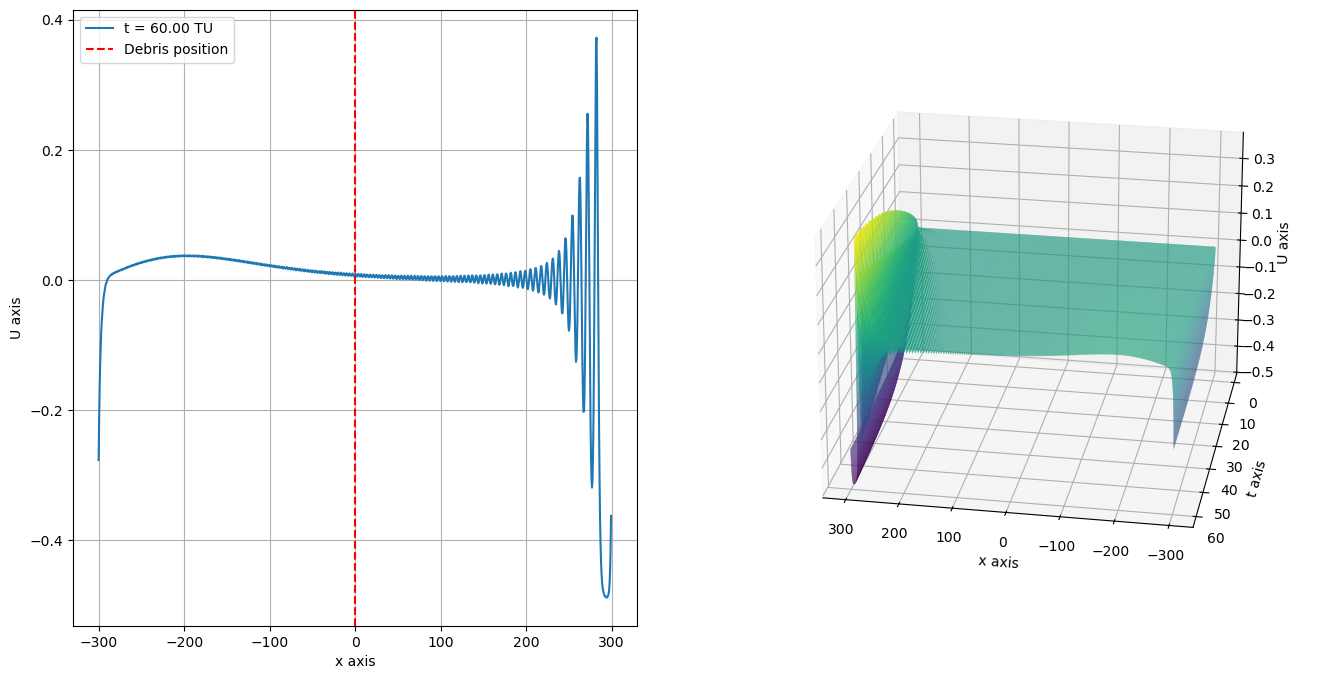

In [132]:

time_tu = 60

sol = num_sol
time_array = num_time_array

print("Plotting Numercal Solution ")
# ---Display the final solution at the last time step---
for i in range(len(time_array)):
    if abs(num_time_array[i] - time_tu) < 1e-2:
        print(i)
        break

Xi, Tau = np.meshgrid(xi, time_array)  # Create meshgrid for plotting

fig = plt.figure(figsize=(16,8))
ax = plt.subplot(121)
ax.plot(xi, sol[i], label=f"t = {time_array[i]:.2f} TU")
ax.axvline(vd_norm * time_array[i] , color='red', linestyle='--', label="Debris position")
#ax.ylim(-1.5,3)
ax.set_xlabel('x axis')
ax.set_ylabel('U axis')
ax.legend()
ax.grid()

ax = plt.subplot(122, projection='3d')
ax.plot_surface(Xi, Tau, sol, rstride=1, cstride=1, cmap='viridis', linewidth=1,antialiased=True)
ax.set_xlabel('x axis')
ax.set_ylabel('t axis')
ax.set_zlabel('U axis')
ax.view_init(elev=23, azim=100, roll=0)

plt.show()

## Analytical results

Plotting Analytical Solution 


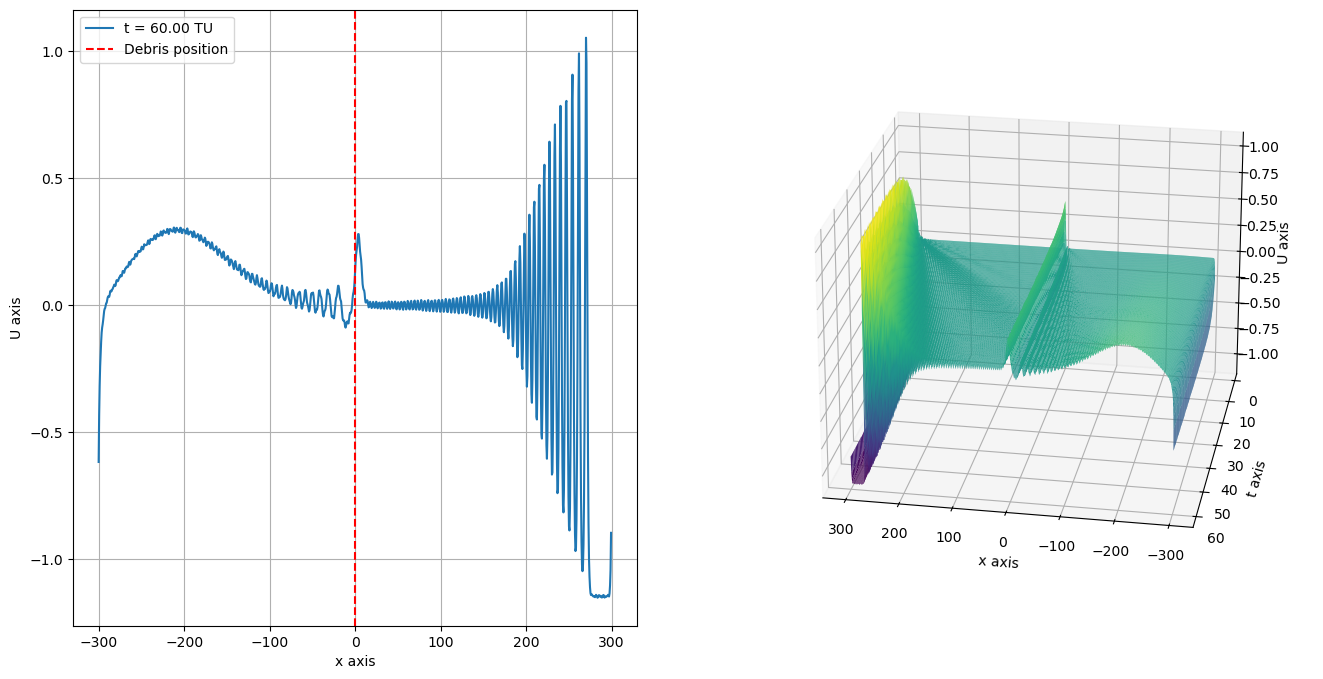

In [133]:

time_tu = 60

sol = anal_sol
time_array = anal_time_array

print("Plotting Analytical Solution ")
# ---Display the final solution at the last time step---
for i in range(len(time_array)):
    if abs(num_time_array[i] - time_tu) < 1e-2:
        print(i)
        break

Xi, Tau = np.meshgrid(xi, time_array)  # Create meshgrid for plotting

fig = plt.figure(figsize=(16,8))
ax = plt.subplot(121)
ax.plot(xi, sol[i], label=f"t = {time_array[i]:.2f} TU")
ax.axvline(vd_norm * time_array[i] , color='red', linestyle='--', label="Debris position")
#ax.ylim(-1.5,3)
ax.set_xlabel('x axis')
ax.set_ylabel('U axis')
ax.legend()
ax.grid()

ax = plt.subplot(122, projection='3d')
ax.plot_surface(Xi, Tau, sol, rstride=1, cstride=1, cmap='viridis', linewidth=1)
ax.set_xlabel('x axis')
ax.set_ylabel('t axis')
ax.set_zlabel('U axis')
ax.view_init(elev=23, azim=100, roll=0)

plt.show()

### Comparing the numerical and analytical solutions

57
579
57.99999999995553 57.99999999995553


Text(0.5, 1.0, 'Comparison of Numerical and Analytical Solutions at Final Time Step')

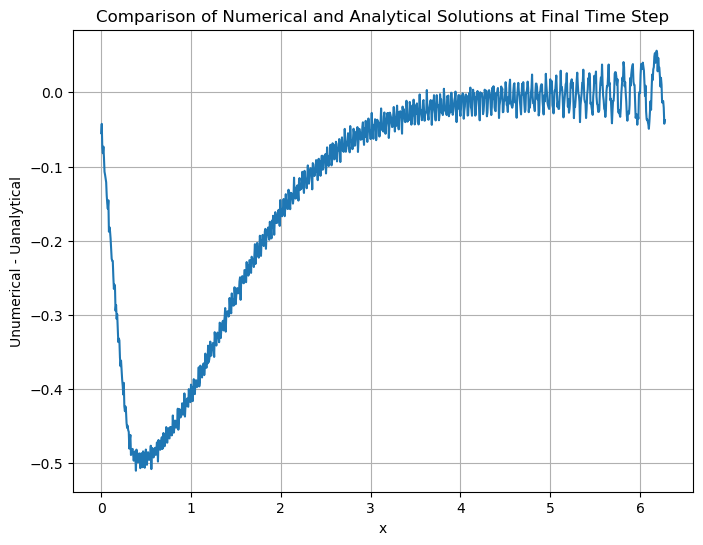

In [125]:
plt.figure(figsize=(8, 6))

time = 58

for i_anal in range(len(anal_time_array)):
    if abs(anal_time_array[i_anal] - time) < 1e-2:
        print(i_anal)
        break
for i_num in range(len(num_time_array)):
    if abs(num_time_array[i_num] - time) < 1e-2:
        print(i_num)
        break

print(num_time_array[i_num], anal_time_array[i_anal])
plt.plot(xi, num_sol[i_num] - anal_sol[i_anal], label="Difference between numerical and analytical solutions")
plt.xlabel("x")
plt.ylabel("Unumerical - Uanalytical")
plt.grid()
plt.title("Comparison of Numerical and Analytical Solutions at Final Time Step")